Figure 1 — Agent behaviour
- A: Label prices relative to \(V_i\); expand x-axis to show nonlinearity.
- B: Keep reservation price versus holdings; label as B.
- C: Replace noisy stubbornness trajectories with smooth expected convergence to a fixed true outcome.
- D: Keep expertise/bias boxplots; clarify that bias shifts the bias-adjusted signal.

Figure 2 — Market validation
- Compare peak cross-correlation with peak lag, distributed-lag delay and shock-response time (T90).
- Select the most informative measure of market responsiveness, distinct from accuracy (MSE).

Figure 3 — Whale influence
- A: Market-price trajectories following whale entry, for different capital shares.
- B: Steady-state distortion versus whale capital share, comparing CLOB simulations with theory (\(\rho\Delta\)).

Figure 4 — Herding effects
- A: Keep the new steady-state distortion plot; reduce to four herding levels.
- B: Replace maximum-error heatmap with convergence factor \(\kappa\) versus herding, comparing theory and simulation.
- Highlight that herding slows or accelerates convergence depending on stubbornness.

Appendix — Theory validation
- Reduce from six to four panels: steady-state distortion, herding amplification, belief-shock convergence and first-passage times.
- Move whale-entry trajectories to Fig. 3 and herding-rate reversal to Fig. 4.
- Emphasize how accurately the analytical approximations reproduce the CLOB simulations.

# possible replace fig 1C

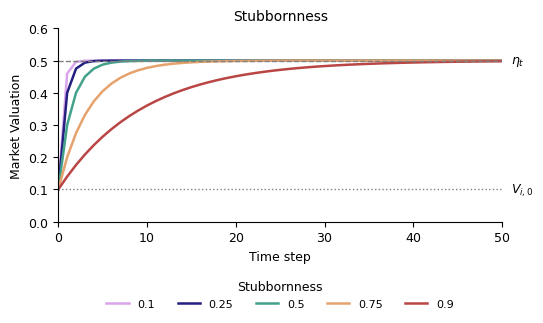

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
eta = 0.5
V0 = 0.1
T = 50
t = np.arange(T + 1)

stubbornness = [0.1, 0.25, 0.5, 0.75, 0.9]
colors = ['#d9a4eb', '#252080', '#43a08b', '#e6a26d', '#ba4545']

fig, ax = plt.subplots(figsize=(5.5, 3.5))

# Expected valuation trajectories
for s, color in zip(stubbornness, colors):
    V = eta + (V0 - eta) * s**t
    ax.plot(t, V, color=color, lw=1.8, label=f'{s:g}')

# Reference lines
ax.axhline(eta, color='gray', ls='--', lw=1)
ax.axhline(V0, color='gray', ls=':', lw=1)

ax.text(T + 1, eta, r'$\eta_t$', va='center')
ax.text(T + 1, V0, r'$V_{i,0}$', va='center')

# Formatting
ax.set(
    xlabel='Time step',
    ylabel='Market Valuation',
    title='Stubbornness',
    xlim=(0, T),
    ylim=(0, 0.6)
)

ax.legend(
    title='Stubbornness',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.25),
    ncol=5,
    frameon=False
)

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# fig 2 - correl / lag measure

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from bettor import bettor, run_market_lob

MAX_LAG = 10

def lagged_correlations(prices, fundamentals, max_lag=MAX_LAG):
    """Corr(Δprice_t, Δfundamental_{t-k}), k=0,...,max_lag."""
    dp = np.diff(np.asarray(prices, float))
    df = np.diff(np.asarray(fundamentals, float))

    out = np.full(max_lag + 1, np.nan)

    for k in range(max_lag + 1):
        x = dp[k:]
        y = df[:len(df)-k]

        if len(x) > 2 and np.std(x) > 1e-12 and np.std(y) > 1e-12:
            out[k] = np.corrcoef(x, y)[0, 1]

    return out


def peak_metrics(prices, fundamentals, max_lag=MAX_LAG):
    """Peak cross-correlation and lag at which it occurs."""
    correlations = lagged_correlations(prices, fundamentals, max_lag)

    if np.all(np.isnan(correlations)):
        return np.nan, np.nan

    lag = int(np.nanargmax(correlations))
    return float(correlations[lag]), lag


def distributed_lag_delay(prices, fundamentals, max_lag=MAX_LAG):
    """
    Estimate Δprice_t = α + Σ β_k Δfundamental_{t-k} + ε_t.

    Return the coefficient-weighted mean lag, using positive
    coefficients only. NaN if no positive response is estimated.
    """
    dp = np.diff(np.asarray(prices, float))
    df = np.diff(np.asarray(fundamentals, float))

    L = max_lag
    if len(dp) <= L + 2:
        return np.nan

    y = dp[L:]
    X = np.column_stack([
        df[L-k:len(df)-k] for k in range(L+1)
    ])
    X = np.column_stack([np.ones(len(y)), X])

    beta = np.linalg.lstsq(X, y, rcond=None)[0][1:]
    weights = np.maximum(beta, 0)

    if weights.sum() <= 1e-12:
        return np.nan

    return float(np.dot(np.arange(L+1), weights) / weights.sum())


def shock_t90(prices, shock_time=100, baseline=0.5,
              new_value=0.6, window=5):
    """
    First time the market reaches 90% of a known step change,
    requiring the condition to hold for 'window' periods.

    Returns NaN if the threshold is not reached.
    """
    prices = np.asarray(prices, float)
    target = baseline + 0.9 * (new_value - baseline)

    for t in range(shock_time, len(prices)-window+1):
        segment = prices[t:t+window]

        if np.all(np.isfinite(segment)) and np.all(segment >= target):
            return float(t - shock_time)

    return np.nan

In [5]:
# Uses the SWEEPS dictionary and _budget_population
# definitions from paper_figures.py.

N_BETTORS = 100
T_MAX = 100
INITIAL_PRICE = 0.5
RW_VARIANCE = 0.05
N_ITER = 30

SHOCK_TIME = 100
SHOCK_POST = 150
SHOCK_SIZE = 0.1

OUTPUT = Path("sim_output")
OUTPUT.mkdir(exist_ok=True)

# If running in a notebook, import these from your script:
from paper_figures import SWEEPS

rows = []

for parameter, (values, make_population) in SWEEPS.items():
    print(f"Running {parameter}...")

    for value_index, value in enumerate(values):
        for iteration in range(N_ITER):

            sweep_index = list(SWEEPS).index(parameter)
            seed = (100_000 * sweep_index
                    + 1_000 * value_index + iteration)

            # Original random-walk experiment
            np.random.seed(seed)
            population = make_population(value)

            record = run_market_lob(
                N_BETTORS, T_MAX, INITIAL_PRICE,
                RW_VARIANCE, population,
                rng=np.random.default_rng(seed)
            )

            prices = np.asarray(record["price_history"], float)
            fundamentals = np.asarray(record["gen_el"], float)

            peak_corr, peak_lag = peak_metrics(prices, fundamentals)
            dl_delay = distributed_lag_delay(prices, fundamentals)

            # Controlled shock experiment
            # Fresh population, matched parameter value and seed.
            np.random.seed(seed)
            shock_population = make_population(value)

            shock_path = np.full(SHOCK_TIME + SHOCK_POST, 0.5)
            shock_path[SHOCK_TIME:] = 0.5 + SHOCK_SIZE

            shock_record = run_market_lob(
                N_BETTORS, len(shock_path), INITIAL_PRICE,
                0.0, shock_population,
                gen_el=shock_path,
                rng=np.random.default_rng(seed)
            )

            shock_prices = np.asarray(
                shock_record["price_history"], float
            )

            rows.append({
                "parameter": parameter,
                "value": float(value),
                "iteration": iteration,
                "seed": seed,
                "mse": np.mean((prices - fundamentals)**2),
                "peak_cross_correlation": peak_corr,
                "peak_lag": peak_lag,
                "distributed_lag": dl_delay,
                "shock_t90": shock_t90(
                    shock_prices,
                    shock_time=SHOCK_TIME,
                    baseline=0.5,
                    new_value=0.5 + SHOCK_SIZE
                )
            })

sweep = pd.DataFrame(rows)
sweep.to_csv(OUTPUT / "figure2_lag_comparison.csv", index=False)

print(f"Completed {len(sweep)} simulations per experiment type.")
print(sweep.groupby("parameter")[
    ["mse", "peak_cross_correlation", "peak_lag",
     "distributed_lag", "shock_t90"]
].mean())

Running Expertise...
Running Bias...
Running Risk Aversion...
Running Stubbornness...
Running Budget Variance...
Completed 1890 simulations per experiment type.
                      mse  peak_cross_correlation  peak_lag  distributed_lag  \
parameter                                                                      
Bias             0.033131                0.559430  2.022222         3.309170   
Budget Variance  0.006208                0.592134  2.000000         3.272009   
Expertise        0.090127                0.289137  3.575758         4.251083   
Risk Aversion    0.006525                0.595240  2.000000         3.283614   
Stubbornness     0.007925                0.570063  2.226316         3.782091   

                 shock_t90  
parameter                   
Bias              1.928571  
Budget Variance   9.613333  
Expertise        29.771875  
Risk Aversion    11.160606  
Stubbornness     14.049123  


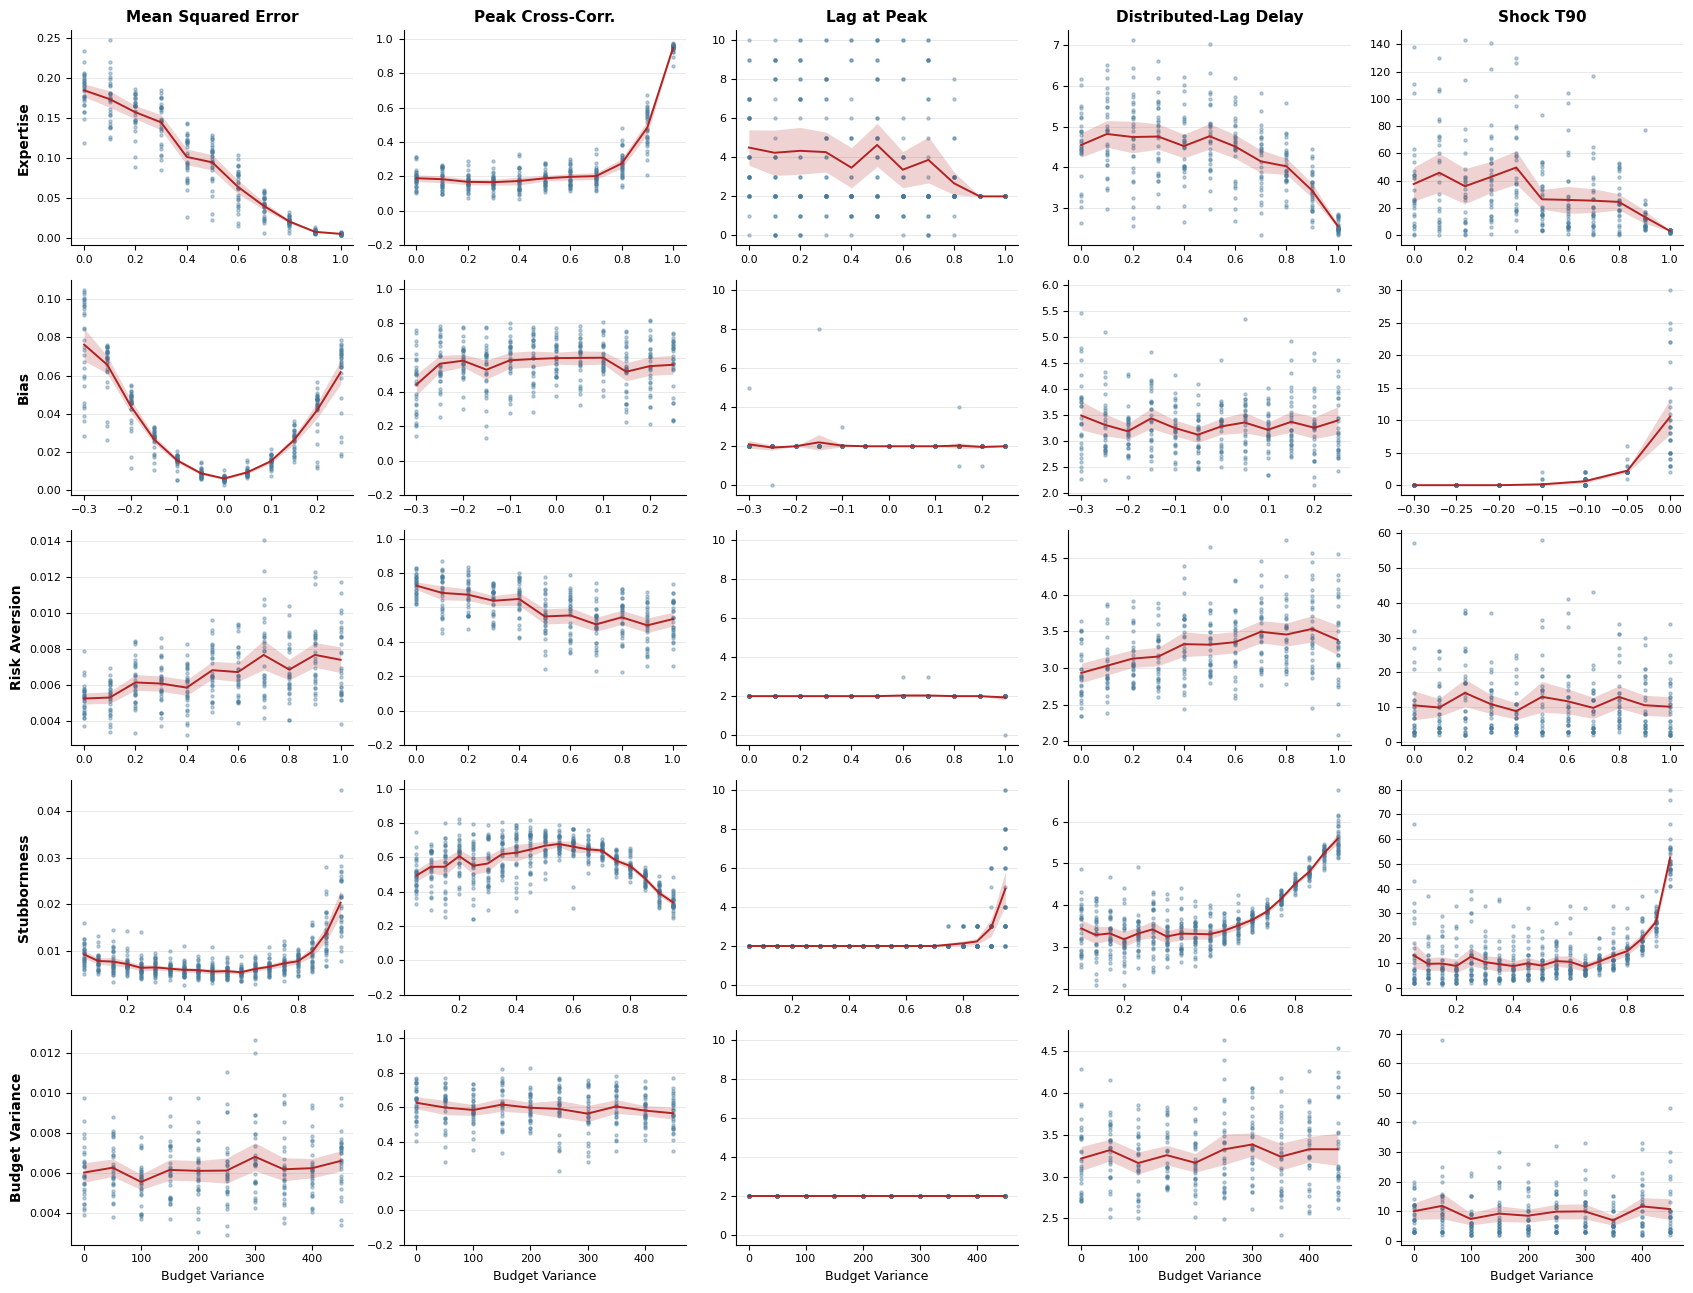


Fraction of missing values by parameter:
                 peak_cross_correlation  peak_lag  distributed_lag  shock_t90
parameter                                                                    
Bias                                0.0       0.0              0.0      0.417
Budget Variance                     0.0       0.0              0.0      0.000
Expertise                           0.0       0.0              0.0      0.030
Risk Aversion                       0.0       0.0              0.0      0.000
Stubbornness                        0.0       0.0              0.0      0.000


In [6]:
from matplotlib.ticker import MaxNLocator

metrics = {
    "mse": "Mean Squared Error",
    "peak_cross_correlation": "Peak Cross-Corr.",
    "peak_lag": "Lag at Peak",
    "distributed_lag": "Distributed-Lag Delay",
    "shock_t90": "Shock T90"
}

parameters = list(SWEEPS)

LINE_COLOR = "#B22222"
POINT_COLOR = "#457B9D"

fig, axes = plt.subplots(
    len(parameters), len(metrics),
    figsize=(17, 13),
    squeeze=False
)

for i, parameter in enumerate(parameters):
    data = sweep[sweep["parameter"] == parameter]

    for j, (column, title) in enumerate(metrics.items()):
        ax = axes[i, j]

        ax.scatter(
            data["value"], data[column],
            s=5, alpha=0.35, color=POINT_COLOR
        )

        stats = data.groupby("value")[column].agg(
            ["mean", "std", "count"]
        )

        ci = 1.96 * stats["std"] / np.sqrt(stats["count"])

        x = stats.index.to_numpy(dtype=float)
        mean = stats["mean"].to_numpy(dtype=float)
        lower = (stats["mean"] - ci).to_numpy(dtype=float)
        upper = (stats["mean"] + ci).to_numpy(dtype=float)

        ax.plot(x, mean, color=LINE_COLOR, lw=1.4)
        ax.fill_between(
            x, lower, upper,
            color=LINE_COLOR, alpha=0.2, linewidth=0
        )

        if i == 0:
            ax.set_title(title, fontsize=11, fontweight="bold")

        if i == len(parameters) - 1:
            ax.set_xlabel(parameter, fontsize=9)

        if j == 0:
            ax.set_ylabel(parameter, fontsize=10, fontweight="bold")

        if column == "peak_cross_correlation":
            ax.set_ylim(-0.2, 1.05)

        if column == "peak_lag":
            ax.set_ylim(-0.5, MAX_LAG + 0.5)
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))

        ax.grid(axis="y", color="#E5E5E5", lw=0.6)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=8)

plt.tight_layout()

fig.savefig(
    "figures/figure2_lag_comparison.pdf",
    bbox_inches="tight"
)
fig.savefig(
    "figures/figure2_lag_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Check missing or unreached metrics
print("\nFraction of missing values by parameter:")
print(
    sweep.groupby("parameter")[
        ["peak_cross_correlation", "peak_lag",
         "distributed_lag", "shock_t90"]
    ].apply(lambda x: x.isna().mean()).round(3)
)

# figs 4

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Parameters
eta = 0.5
W = 0.7
Delta = W - eta

rho_values = np.linspace(0, 0.65, 300)
h_values = np.linspace(0, 0.9, 300)

s_fixed = 0.3
rho_fixed = 0.3

cmap = LinearSegmentedColormap.from_list(
    "herding", ["#E040FB", "#9F9AFF", "#18D9EB"]
)

def steady_state_error(rho, h, s, Delta):
    numerator = (1-h)*(1-s) + h
    denominator = (1-h)*(1-s) + h*rho
    return rho * Delta * numerator / denominator

def convergence_factor(rho, h, s):
    return (1-h)*s + h*(1-rho)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# -------------------------------------------------
# A — Herding amplifies steady-state distortion
# -------------------------------------------------

ax = axes[0]

herding_levels = [0, 0.3, 0.6, 0.9]

for h in herding_levels:
    error = steady_state_error(
        rho_values, h, s_fixed, Delta
    )

    ax.plot(
        rho_values, error,
        color=cmap(h),
        lw=2.5,
        label=fr"$h={h:g}$"
    )

ax.set(
    xlabel=r"Whale capital share ($\rho$)",
    ylabel=r"Steady-state price error ($p_S-\eta$)",
    title="A  Steady-state distortion",
    xlim=(0, 0.65),
    ylim=(0, 0.21)
)

ax.legend(
    title="Herding strength",
    frameon=False,
    fontsize=9
)

# -------------------------------------------------
# B — Herding changes convergence speed
# -------------------------------------------------

ax = axes[1]

stubbornness_levels = [0.3, 0.5, 0.7, 0.9]

for s in stubbornness_levels:
    kappa = convergence_factor(
        rho_fixed, h_values, s
    )

    ax.plot(
        h_values, kappa,
        lw=2.5,
        label=fr"$s={s:g}$"
    )

ax.axhline(
    1-rho_fixed,
    color="gray",
    ls="--",
    lw=1
)

ax.set(
    xlabel=r"Herding strength ($h$)",
    ylabel=r"Convergence factor ($\kappa$)",
    title="B  Convergence speed",
    xlim=(0, 0.9),
    ylim=(0.25, 1)
)

ax.legend(
    title="Stubbornness",
    frameon=False,
    fontsize=9
)

# Shared styling
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

# fig 3

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bettor import bettor, run_market_lob

N = 100
T = 250
ENTRY = 50
ETA = 0.5
W = 0.7
DELTA = W - ETA

RHOS = [0, 0.2, 0.4, 0.6]
RUNS = 100

rows = []

for rho in RHOS:
    print(f"Running rho = {rho}")

    for run in range(RUNS):
        seed = 1000 + run
        np.random.seed(seed)

        agents = [
            bettor(
                budget=100,
                expertise=0.95,
                market_imitation=0
            )
            for _ in range(N)
        ]

        path = np.full(T, ETA)

        record = run_market_lob(
            N, T, ETA, 0,
            agents,
            gen_el=path,
            whale_share=rho,
            whale_start=ENTRY,
            whale_valuation=W,
            rng=np.random.default_rng(seed)
        )

        prices = (
            pd.Series(record["midquote"])
            .ffill()
            .fillna(ETA)
            .to_numpy()
        )

        for t, price in enumerate(prices):
            rows.append({
                "rho": rho,
                "run": run,
                "time": t,
                "price": price,
                "error": price - ETA
            })

df = pd.DataFrame(rows)

Running rho = 0
Running rho = 0.2
Running rho = 0.4
Running rho = 0.6


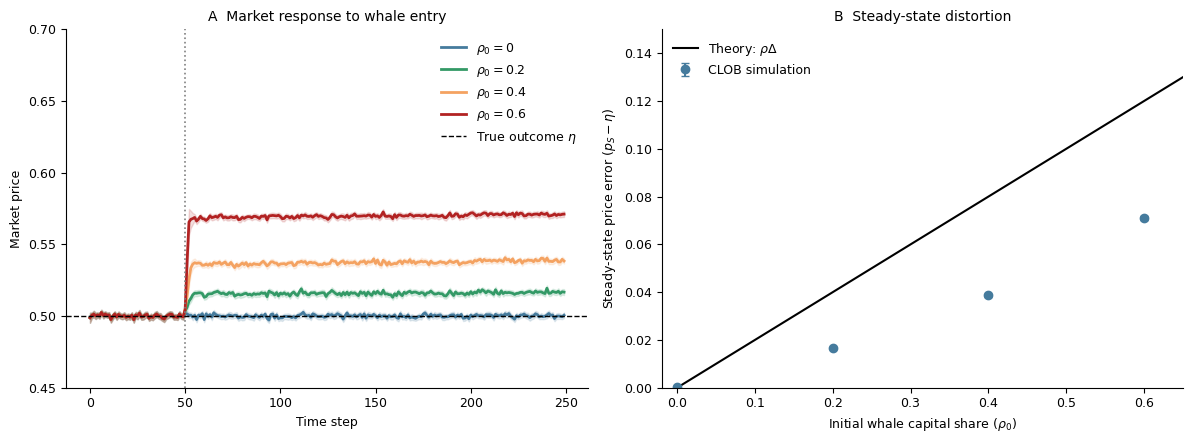

In [8]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "whale", ["#457B9D", "#339966", "#F4A261", "#B22222"]
)

colors = [cmap(i / (len(RHOS)-1)) for i in range(len(RHOS))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# A — Price trajectories
ax = axes[0]

for rho, color in zip(RHOS, colors):
    data = df[df["rho"] == rho]

    stats = data.groupby("time")["price"].agg(
        ["mean", "std", "count"]
    )

    x = stats.index.to_numpy()
    mean = stats["mean"].to_numpy()
    ci = 1.96 * stats["std"].to_numpy() / np.sqrt(
        stats["count"].to_numpy()
    )

    ax.plot(x, mean, color=color, lw=2,
            label=fr"$\rho_0={rho:g}$")
    ax.fill_between(x, mean-ci, mean+ci,
                    color=color, alpha=0.15)

ax.axvline(ENTRY, color="gray", ls=":", lw=1.2)
ax.axhline(ETA, color="black", ls="--", lw=1,
           label=r"True outcome $\eta$")

ax.set(
    xlabel="Time step",
    ylabel="Market price",
    title="A  Market response to whale entry",
    ylim=(0.45, 0.7)
)
ax.legend(frameon=False, fontsize=9)

# B — Steady-state error
ax = axes[1]

steady = (
    df[df["time"] >= T-50]
    .groupby(["rho", "run"])["error"]
    .mean()
    .reset_index()
)

stats = steady.groupby("rho")["error"].agg(
    ["mean", "std", "count"]
)

x = stats.index.to_numpy()
y = stats["mean"].to_numpy()
ci = 1.96 * stats["std"].to_numpy() / np.sqrt(
    stats["count"].to_numpy()
)

ax.errorbar(
    x, y, yerr=ci,
    fmt="o", color="#457B9D",
    capsize=3, label="CLOB simulation"
)

rho_grid = np.linspace(0, 0.65, 100)

ax.plot(
    rho_grid, rho_grid * DELTA,
    color="black", lw=1.5,
    label=r"Theory: $\rho\Delta$"
)

ax.set(
    xlabel=r"Initial whale capital share ($\rho_0$)",
    ylabel=r"Steady-state price error ($p_S-\eta$)",
    title="B  Steady-state distortion",
    xlim=(-0.02, 0.65),
    ylim=(0, 0.15)
)

ax.legend(frameon=False, fontsize=9)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# new appendix

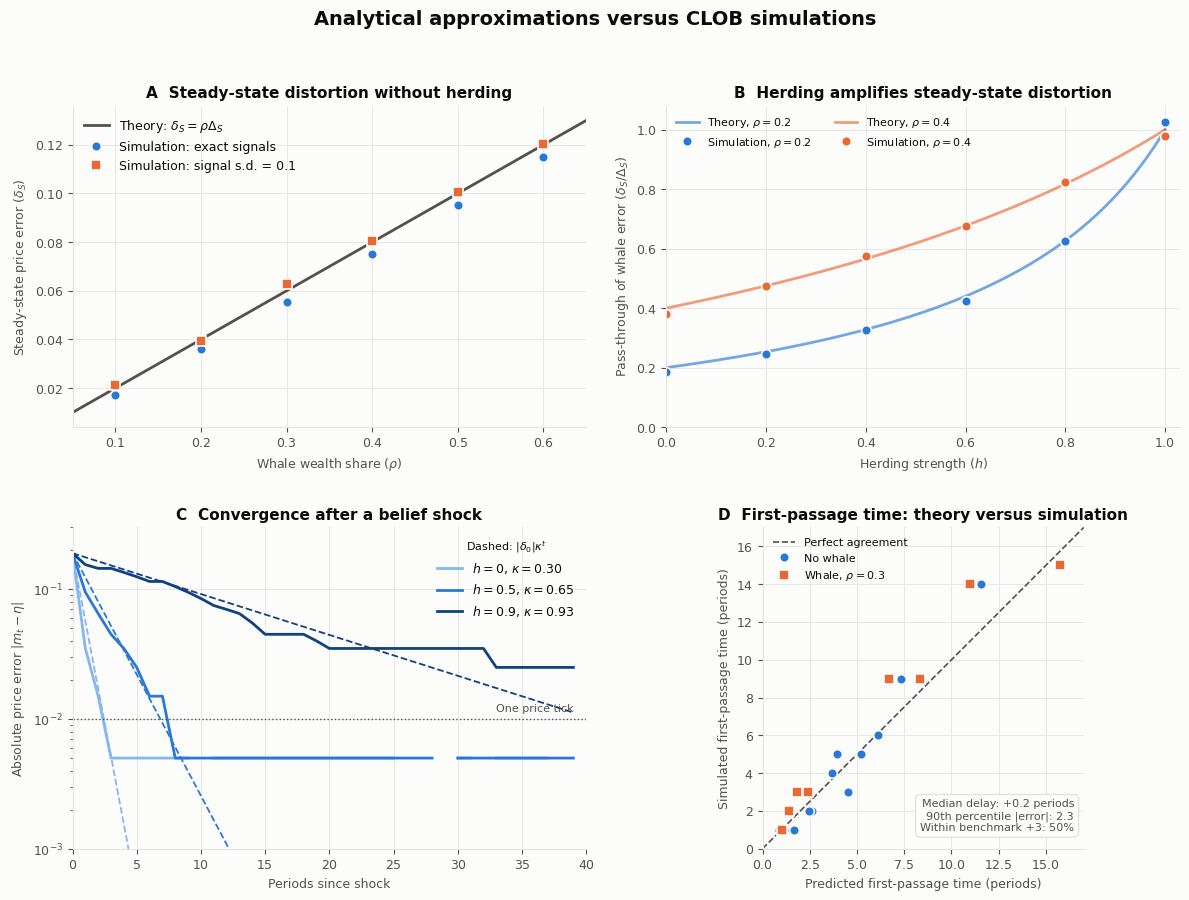

In [11]:
import json
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Load existing simulation results
# ============================================================

with open("theory_checks/figdata_AB.json") as f:
    ab = json.load(f)

with open("theory_checks/figdata_CD.json") as f:
    cd = json.load(f)

with open("theory_checks/figdata_shock.json") as f:
    sh = json.load(f)

# ============================================================
# Styling (from original appendix figure)
# ============================================================

SURF = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
GRID = "#e4e3df"

BLUE = "#2a78d6"
ORANGE = "#eb6834"
RAMP = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURF,
    "axes.facecolor": SURF,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK2,
    "xtick.color": INK2,
    "ytick.color": INK2,
    "text.color": INK,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 2,
})

dot = dict(marker="o", ms=7, mec=SURF, mew=1.2, ls="none")
sq = dict(dot, marker="s")

DELTA = 0.2
S = 0.3

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
ax = axes.ravel()

# ============================================================
# A — Steady-state distortion without herding
# ============================================================

a = np.asarray(ab["A"])
rho = np.linspace(0.05, 0.65, 200)

ax[0].plot(
    rho, rho * DELTA,
    color=INK2,
    label=r"Theory: $\delta_S=\rho\Delta_S$"
)

no_noise = a[a[:, 1] == 0]
with_noise = a[a[:, 1] > 0]

ax[0].plot(
    no_noise[:, 0], no_noise[:, 2],
    color=BLUE,
    label="Simulation: exact signals",
    **dot
)

ax[0].plot(
    with_noise[:, 0], with_noise[:, 2],
    color=ORANGE,
    label="Simulation: signal s.d. = 0.1",
    **sq
)

ax[0].set(
    title="A  Steady-state distortion without herding",
    xlabel=r"Whale wealth share ($\rho$)",
    ylabel=r"Steady-state price error ($\delta_S$)",
    xlim=(0.05, 0.65)
)

ax[0].legend(loc="upper left")


# ============================================================
# B — Herding amplification: theory versus simulation
# ============================================================

b = np.asarray(ab["B"])
h_grid = np.linspace(0, 1, 200)

for rho, color in [(0.2, BLUE), (0.4, ORANGE)]:

    theory = (
        rho * ((1-h_grid)*(1-S) + h_grid)
        / ((1-h_grid)*(1-S) + h_grid*rho)
    )

    ax[1].plot(
        h_grid, theory,
        color=color, alpha=0.65,
        label=fr"Theory, $\rho={rho}$"
    )

    selected = b[np.isclose(b[:, 0], rho)]

    ax[1].plot(
        selected[:, 1], selected[:, 2],
        color=color,
        label=fr"Simulation, $\rho={rho}$",
        **dot
    )

ax[1].set(
    title="B  Herding amplifies steady-state distortion",
    xlabel=r"Herding strength ($h$)",
    ylabel=r"Pass-through of whale error ($\delta_S/\Delta_S$)",
    xlim=(0, 1.03),
    ylim=(0, 1.08)
)

ax[1].legend(loc="upper left", ncol=2, fontsize=8)


# ============================================================
# C — Convergence after a belief shock
# ============================================================

TICK = 0.01

for h, color in zip(["0", "0.5", "0.9"], RAMP):

    error = np.asarray(cd["D"][h], dtype=float)
    h_value = float(h)

    # No-whale convergence factor
    kappa = h_value + (1-h_value)*S

    t = np.arange(len(error))

    observed = np.abs(error)
    predicted = abs(error[0]) * kappa**t

    # Mask zeros rather than artificially adding a constant
    observed = np.where(observed > 0, observed, np.nan)
    predicted = np.where(predicted > 0, predicted, np.nan)

    ax[2].plot(
        t, observed,
        color=color,
        label=fr"$h={h}$, $\kappa={kappa:.2f}$"
    )

    ax[2].plot(
        t, predicted,
        color=color,
        ls="--", lw=1.3
    )

ax[2].axhline(
    TICK,
    color=INK2, ls=":", lw=1
)

ax[2].text(
    39, TICK*1.15,
    "One price tick",
    ha="right", fontsize=8, color=INK2
)

ax[2].set(
    title="C  Convergence after a belief shock",
    xlabel="Periods since shock",
    ylabel=r"Absolute price error $|m_t-\eta|$",
    yscale="log",
    ylim=(1e-3, 0.3),
    xlim=(0, 40)
)

ax[2].legend(
    loc="upper right",
    title=r"Dashed: $|\delta_0|\kappa^t$",
    title_fontsize=8
)


# ============================================================
# D — First-passage times: theory versus CLOB
# ============================================================

tb = np.array([x["T_bench"] for x in sh], dtype=float)
ts = np.array([x["T_sim"] for x in sh], dtype=float)
whale = np.array([x["rho"] > 0 for x in sh])

valid = np.isfinite(tb) & np.isfinite(ts)

lim = max(17, np.nanmax(np.r_[tb[valid], ts[valid]]) + 1)

ax[3].plot(
    [0, lim], [0, lim],
    color=INK2, lw=1.2, ls="--",
    label="Perfect agreement"
)

ax[3].plot(
    tb[valid & ~whale],
    ts[valid & ~whale],
    color=BLUE,
    label="No whale",
    **dot
)

ax[3].plot(
    tb[valid & whale],
    ts[valid & whale],
    color=ORANGE,
    label=r"Whale, $\rho=0.3$",
    **sq
)

# Summary statistics
difference = ts[valid] - tb[valid]

median_difference = np.median(difference)
p90_absolute = np.percentile(np.abs(difference), 90)
within_three = np.mean(
    (difference >= 0) & (difference <= 3)
)

summary = (
    f"Median delay: {median_difference:+.1f} periods\n"
    f"90th percentile |error|: {p90_absolute:.1f}\n"
    f"Within benchmark +3: {within_three:.0%}"
)

ax[3].text(
    0.97, 0.05, summary,
    transform=ax[3].transAxes,
    ha="right", va="bottom",
    fontsize=8,
    color=INK2,
    bbox=dict(
        facecolor=SURF,
        edgecolor=GRID,
        boxstyle="round,pad=0.4"
    )
)

ax[3].set(
    title="D  First-passage time: theory versus simulation",
    xlabel="Predicted first-passage time (periods)",
    ylabel="Simulated first-passage time (periods)",
    xlim=(0, lim),
    ylim=(0, lim)
)

ax[3].set_aspect("equal", adjustable="box")
ax[3].legend(loc="upper left", fontsize=8)


# ============================================================
# Final formatting and save
# ============================================================

for a in ax:
    a.tick_params(labelsize=9)
    a.set_axisbelow(True)

fig.suptitle(
    "Analytical approximations versus CLOB simulations",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.tight_layout(rect=(0, 0, 1, 0.965), h_pad=2.5, w_pad=2)

fig.savefig(
    "clob_theory_checks_appendix.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "clob_theory_checks_appendix.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

In [12]:
np.mean((difference >= 0) & (difference <= 3)), np.mean(np.abs(difference) <= 3)

(np.float64(0.5), np.float64(0.95))

# convergence plot - possibly in fig 4?

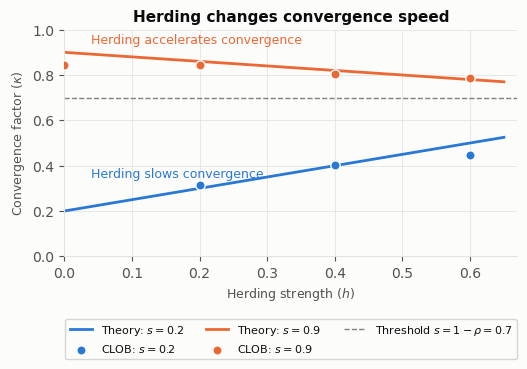

In [16]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Load existing simulation results
with open("theory_checks/figdata_shock.json") as f:
    data = json.load(f)

# Parameters
rho = 0.3
s_values = [0.2, 0.9]
h_grid = np.linspace(0, 0.65, 200)

colors = {
    0.2: "#2a78d6",
    0.9: "#eb6834"
}

def kappa(h, s, rho):
    return (1 - h)*s + h*(1 - rho)

fig, ax = plt.subplots(figsize=(5.5, 4))

for s in s_values:
    color = colors[s]

    # Theoretical prediction
    ax.plot(
        h_grid,
        kappa(h_grid, s, rho),
        color=color,
        lw=2,
        label=fr"Theory: $s={s}$"
    )

    # CLOB simulation estimates
    selected = [
        x for x in data
        if np.isclose(x["rho"], rho)
        and np.isclose(x["s"], s)
        and np.isfinite(x["kappa_emp"])
    ]

    ax.scatter(
        [x["h"] for x in selected],
        [x["kappa_emp"] for x in selected],
        color=color,
        s=45,
        edgecolor="white",
        linewidth=1,
        zorder=3,
        label=fr"CLOB: $s={s}$"
    )

# Reversal threshold
ax.axhline(
    1 - rho,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=fr"Threshold $s=1-\rho={1-rho:.1f}$"
)

ax.set(
    xlabel=r"Herding strength ($h$)",
    ylabel=r"Convergence factor ($\kappa$)",
    title="Herding changes convergence speed",
    xlim=(0, 0.67),
    ylim=(0, 1)
)

ax.text(
    0.04, 0.35,
    "Herding slows convergence",
    color=colors[0.2],
    fontsize=9
)

ax.text(
    0.04, 0.94,
    "Herding accelerates convergence",
    color=colors[0.9],
    fontsize=9
)
# move legend below the plot
ax.legend(frameon=True, fontsize=8, bbox_to_anchor=(0.5, -0.25), loc="upper center", ncol=3)

ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("figures/herding_rate_reversal.pdf", bbox_inches="tight")
plt.savefig("figures/herding_rate_reversal.png", dpi=250, bbox_inches="tight")
plt.show()